# 02a — Preprocessing demo and validation (MVTec AD)

**Goal:** check, on the *real* MVTec AD images, that our existing preprocessing code behaves correctly before we start PCA.

This notebook **reuses** the code in the repository (`src/data/dataset.py`, `src/data/preprocessing.py`, `src/data/pipelines.py`). It does not re-implement any preprocessing.

Rules this notebook follows:
- Dataset files are only **read**, never written or modified.
- **No data augmentation.**
- **No test images are used for training or validation.** Nothing is fitted here at all; test images are only inspected.
- Every number you see is computed live in your Colab session. Nothing is hard-coded.

| Section | What it does |
|---|---|
| 1 | Mount Drive, load the repo, build the three preprocessors |
| 2 | Load real RGB and grayscale-stored images + defect masks |
| 3 | Step-by-step preprocessing (resize, grayscale/RGB, normalise, tensor) |
| 4 | Original vs processed images and masks |
| 5 | Tensor shapes, dtypes, ranges, pixel statistics |
| 6 | Check all 15 categories (shapes, ranges, NaN/Inf, masks, split leakage) |
| 7 | PCA-specific readiness check |
| 8 | Validation summary and PCA go / no-go |

Run the cells from top to bottom.

## 1. Setup: Drive, repository, imports

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, sys, subprocess
from pathlib import Path

REPO_URL = 'https://github.com/pranitas-cloud/CS-663.git'
REPO = Path('/content/CS-663')

if not REPO.exists():
    out = subprocess.run(['git', 'clone', REPO_URL, str(REPO)], capture_output=True, text=True)
else:
    out = subprocess.run(['git', '-C', str(REPO), 'pull', 'origin', 'main'], capture_output=True, text=True)
print((out.stdout + out.stderr).strip())
assert REPO.exists(), 'Repository not found. Check the clone output above.'

os.chdir(REPO)                      # config path below is relative to the repo root
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))   # makes `import src...` work
print('Working directory:', Path.cwd())

Mounted at /content/drive
Cloning into '/content/CS-663'...
Working directory: /content/CS-663


In [2]:
import copy
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from torch.utils.data import Subset

# --- our existing repository code (names verified against the repo) ---
from src.data.dataset import MVTecDataset, available_categories
from src.data.pipelines import build_preprocessor, build_dataset, load_config, stack_images
from src.data.preprocessing import (
    image_to_tensor,
    resize_image,
    normalize_imagenet,
    denormalize_imagenet,
    mask_to_tensor,
)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

In [3]:
DATA_ROOT = Path('/content/drive/MyDrive/CS663_Shared/datasets/mvtec_anomaly_detection')
assert DATA_ROOT.is_dir(), f'Dataset root not found: {DATA_ROOT}'

# Load the repo config, but point it at the Drive copy of the data (in memory only; the YAML file is not changed).
cfg = copy.deepcopy(load_config('configs/default.yaml'))
cfg['data']['root'] = str(DATA_ROOT)
IMAGE_SIZE = cfg['data']['image_size']

categories = available_categories(DATA_ROOT)
print(f'{len(categories)} categories found:', categories)
assert len(categories) == 15, 'Expected 15 MVTec AD categories.'

METHODS = ('pca', 'autoencoder', 'patchcore')
preprocessors = {m: build_preprocessor(m, cfg) for m in METHODS}
for m, p in preprocessors.items():
    print(f'\n[{m}]')
    for k, v in p.describe().items():
        print(f'  {k}: {v}')

15 categories found: ['bottle', 'cable', 'capsule', 'carpet', 'grid', 'hazelnut', 'leather', 'metal_nut', 'pill', 'screw', 'tile', 'toothbrush', 'transistor', 'wood', 'zipper']

[pca]
  method: pca
  image_size: 256
  channels: 1
  resize: bilinear, antialias=True, square, no crop
  mask_resize: nearest
  scaling: [0,1]
  centring: done in PCA fit on train only
  patch_size: 32
  stride: 16
  patch_grid: (15, 15)

[autoencoder]
  method: autoencoder
  image_size: 256
  channels: 3
  resize: bilinear, antialias=True, square, no crop
  mask_resize: nearest
  scaling: [0,1] (no mean/std)
  augmentation: none
  divisible_by: 32

[patchcore]
  method: patchcore
  image_size: 256
  channels: 3
  resize: bilinear, antialias=True, square, no crop
  mask_resize: nearest
  scaling: [0,1] then ImageNet mean/std
  center_crop: None


## 2. Load real images from representative categories

- `bottle` is stored as **RGB**.
- `grid` is stored as **single-channel grayscale** (`L`).

We load the first *defective* test image of each (so it has a ground-truth mask) with the existing `MVTecDataset` loader. The loader returns the original arrays untouched.

In [4]:
REPRESENTATIVE = {'RGB-stored': 'bottle', 'grayscale-stored': 'grid'}

def first_defective_item(category):
    ds = MVTecDataset(DATA_ROOT, category, split='test')
    idx = next(i for i, s in enumerate(ds.samples) if s[2] != 'good')
    return ds[idx]

raw_items = {}
for kind, cat in REPRESENTATIVE.items():
    item = first_defective_item(cat)
    raw_items[cat] = item
    img, msk = item['image'], item['mask']
    print(f'{cat:8s} ({kind})  defect={item["defect_type"]}')
    print(f'   file : {Path(item["image_path"]).relative_to(DATA_ROOT)}')
    print(f'   image: shape={img.shape} dtype={img.dtype} min={img.min()} max={img.max()}')
    print(f'   mask : shape={msk.shape} dtype={msk.dtype} unique values={np.unique(msk).tolist()}')

assert raw_items['bottle']['image'].ndim == 3, 'bottle was expected to be RGB'
assert raw_items['grid']['image'].ndim == 2, 'grid was expected to be single-channel'

bottle   (RGB-stored)  defect=broken_large
   file : bottle/test/broken_large/000.png
   image: shape=(900, 900, 3) dtype=uint8 min=27 max=255
   mask : shape=(900, 900) dtype=uint8 unique values=[0, 255]
grid     (grayscale-stored)  defect=bent
   file : grid/test/bent/000.png
   image: shape=(1024, 1024) dtype=uint8 min=36 max=198
   mask : shape=(1024, 1024) dtype=uint8 unique values=[0, 255]


## 3. Preprocessing step by step

One image, one primitive at a time, using the repo functions directly:

1. `image_to_tensor` : uint8 array → float tensor `C×H×W` in [0, 1]. With `grayscale=True`, RGB becomes luminance; a single-channel source is used as-is. With `grayscale=False`, a single-channel source is copied to 3 channels.
2. `resize_image` : anti-aliased bilinear resize to `IMAGE_SIZE × IMAGE_SIZE`.
3. `normalize_imagenet` : ImageNet mean/std (used by PatchCore only).
4. `mask_to_tensor` : mask → `1×S×S` tensor of 0/1 using nearest-neighbour resizing.

In [5]:
def tensor_stats(t):
    return {
        'shape': tuple(t.shape),
        'dtype': str(t.dtype).replace('torch.', ''),
        'min': round(t.min().item(), 4),
        'max': round(t.max().item(), 4),
        'mean': round(t.mean().item(), 4),
        'std': round(t.std().item(), 4),
    }

rows = []
for cat, item in raw_items.items():
    raw = item['image']
    steps = {}
    steps['1a. image_to_tensor (RGB, 3ch)']       = image_to_tensor(raw, grayscale=False)
    steps['1b. image_to_tensor (grayscale, 1ch)'] = image_to_tensor(raw, grayscale=True)
    steps['2a. resize_image (RGB)']               = resize_image(steps['1a. image_to_tensor (RGB, 3ch)'], IMAGE_SIZE)
    steps['2b. resize_image (grayscale)']         = resize_image(steps['1b. image_to_tensor (grayscale, 1ch)'], IMAGE_SIZE)
    steps['3.  normalize_imagenet (RGB)']         = normalize_imagenet(steps['2a. resize_image (RGB)'])
    steps['4.  mask_to_tensor (nearest)']         = mask_to_tensor(item['mask'], IMAGE_SIZE, mode='nearest')
    for name, t in steps.items():
        rows.append({'category': cat, 'step': name, **tensor_stats(t)})

pd.DataFrame(rows)

,category,step,shape,dtype,min,max,mean,std
0,bottle,"1a. image_to_tensor (RGB, 3ch)","(3, 900, 900)",float32,0.1059,1.0000,0.5466,0.3578
1,bottle,"1b. image_to_tensor (grayscale, 1ch)","(1, 900, 900)",float32,0.1186,0.9999,0.5426,0.3611
2,bottle,2a. resize_image (RGB),"(3, 256, 256)",float32,0.1177,1.0000,0.5466,0.3571
3,bottle,2b. resize_image (grayscale),"(1, 256, 256)",float32,0.1278,0.9999,0.5426,0.3604
4,bottle,3. normalize_imagenet (RGB),"(3, 256, 256)",float32,-1.6038,2.6400,0.4326,1.5893
5,bottle,4. mask_to_tensor (nearest),"(1, 256, 256)",float32,0.0000,1.0000,0.1088,0.3114
6,grid,"1a. image_to_tensor (RGB, 3ch)","(3, 1024, 1024)",float32,0.1412,0.7765,0.4467,0.1240
7,grid,"1b. image_to_tensor (grayscale, 1ch)","(1, 1024, 1024)",float32,0.1412,0.7765,0.4467,0.1240
8,grid,2a. resize_image (RGB),"(3, 256, 256)",float32,0.1805,0.6866,0.4467,0.1139
9,grid,2b. resize_image (grayscale),"(1, 256, 256)",float32,0.1805,0.6866,0.4467,0.1139


## 4. Original vs processed

Each processed image comes from the full pipeline object (`pre(image, mask)`), i.e. exactly what the methods will receive. PatchCore's output is ImageNet-standardised, so for display only we undo that with `denormalize_imagenet`.

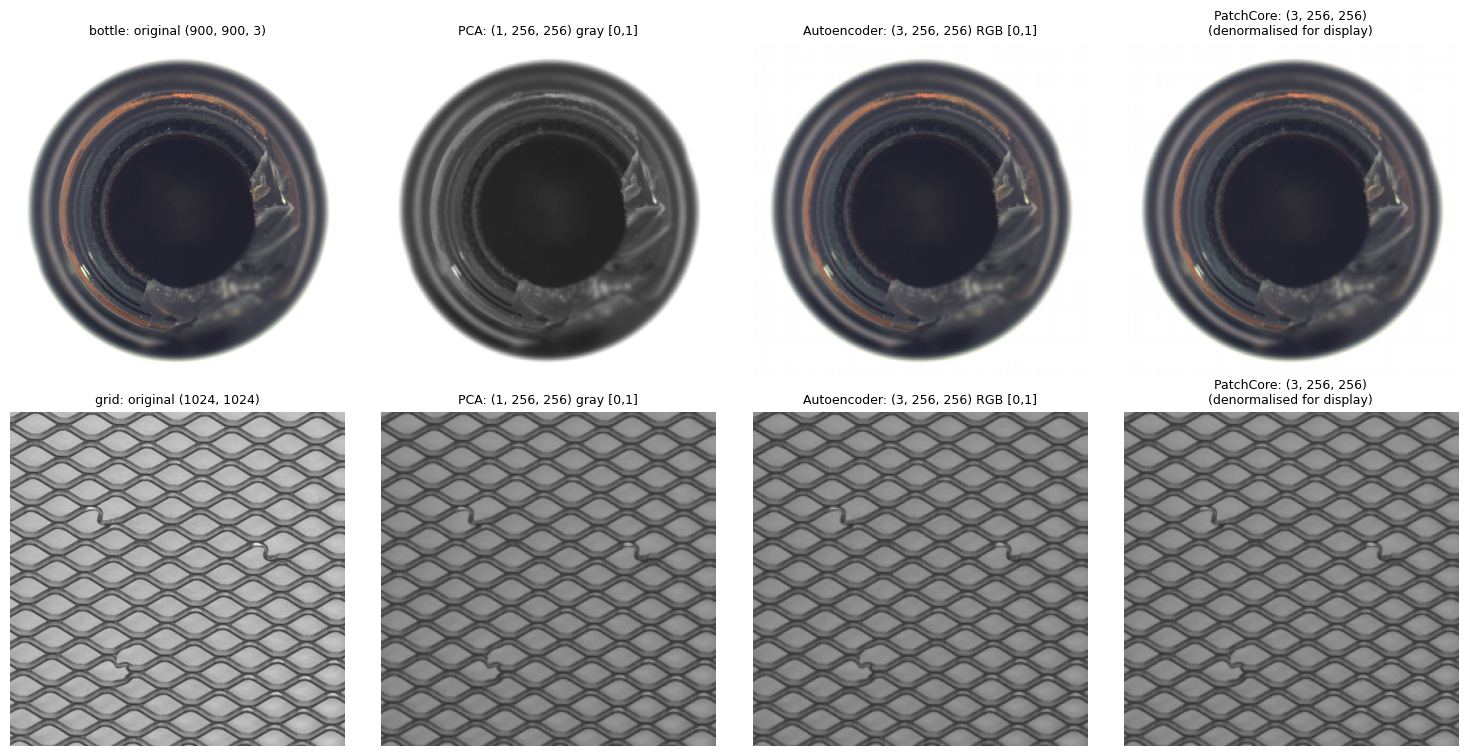

In [6]:
def show(ax, arr, title):
    if arr.ndim == 2:
        ax.imshow(arr, cmap='gray', vmin=0, vmax=arr.max() if arr.max() > 1 else 1)
    else:
        ax.imshow(arr)
    ax.set_title(title, fontsize=9)
    ax.axis('off')

def t2np(t):
    a = t.clamp(0, 1).permute(1, 2, 0).numpy()
    return a[..., 0] if a.shape[2] == 1 else a

fig, axes = plt.subplots(len(raw_items), 4, figsize=(15, 3.8 * len(raw_items)))
for r, (cat, item) in enumerate(raw_items.items()):
    raw = item['image']
    show(axes[r, 0], raw, f'{cat}: original {raw.shape}')
    x_pca, _ = preprocessors['pca'](raw, item['mask'])
    x_ae,  _ = preprocessors['autoencoder'](raw, item['mask'])
    x_pc,  _ = preprocessors['patchcore'](raw, item['mask'])
    show(axes[r, 1], t2np(x_pca), f'PCA: {tuple(x_pca.shape)} gray [0,1]')
    show(axes[r, 2], t2np(x_ae),  f'Autoencoder: {tuple(x_ae.shape)} RGB [0,1]')
    show(axes[r, 3], t2np(denormalize_imagenet(x_pc)), f'PatchCore: {tuple(x_pc.shape)}\n(denormalised for display)')
plt.tight_layout(); plt.show()

bottle: defect area before = 10.8879%  |  after = 10.8795%
grid: defect area before = 0.5207%  |  after = 0.5249%


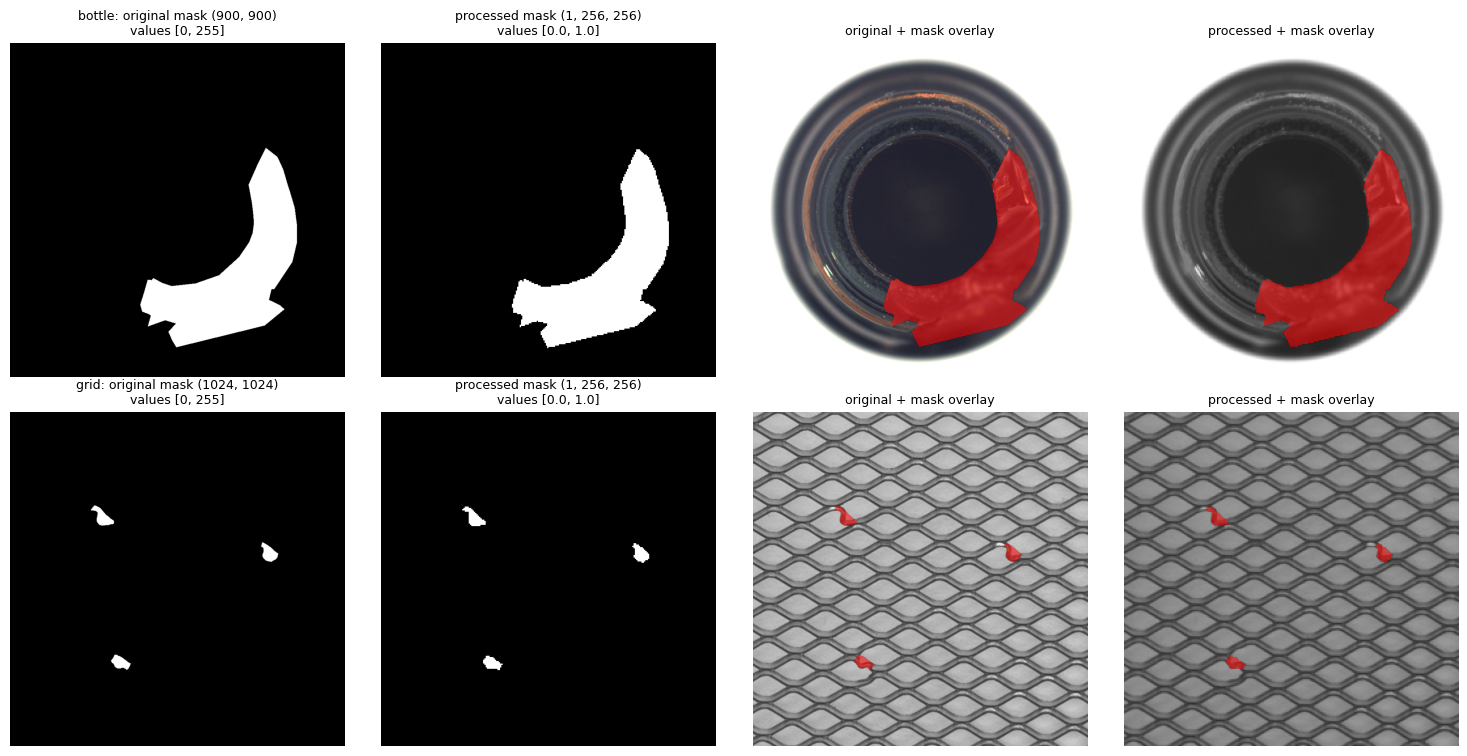

In [7]:
# Original vs processed defect masks (+ overlay on the image so alignment is visible)
fig, axes = plt.subplots(len(raw_items), 4, figsize=(15, 3.8 * len(raw_items)))
for r, (cat, item) in enumerate(raw_items.items()):
    raw, raw_mask = item['image'], item['mask']
    x, m = preprocessors['pca'](raw, raw_mask)          # same mask tensor for every method
    m2 = m[0].numpy()

    show(axes[r, 0], raw_mask, f'{cat}: original mask {raw_mask.shape}\nvalues {np.unique(raw_mask).tolist()}')
    show(axes[r, 1], m2, f'processed mask {tuple(m.shape)}\nvalues {np.unique(m2).tolist()}')

    show(axes[r, 2], raw, 'original + mask overlay')
    axes[r, 2].imshow(np.ma.masked_where(raw_mask == 0, raw_mask), cmap='autumn', alpha=0.55)
    show(axes[r, 3], t2np(x), 'processed + mask overlay')
    axes[r, 3].imshow(np.ma.masked_where(m2 == 0, m2), cmap='autumn', alpha=0.55)

    print(f'{cat}: defect area before = {(raw_mask > 0).mean():.4%}  |  after = {m2.mean():.4%}')
plt.tight_layout(); plt.show()

## 5. Tensor shapes, dtypes, ranges, pixel statistics

Output of the full pipelines for the two representative images (not just the primitives).

In [8]:
rows = []
for cat, item in raw_items.items():
    for m, pre in preprocessors.items():
        x, y = pre(item['image'], item['mask'])
        ch_means = [round(v, 3) for v in x.mean(dim=(1, 2)).tolist()]
        rows.append({'category': cat, 'method': m, 'tensor': 'image', **tensor_stats(x),
                     'finite': bool(torch.isfinite(x).all()), 'channel_means': ch_means})
        rows.append({'category': cat, 'method': m, 'tensor': 'mask', **tensor_stats(y),
                     'finite': bool(torch.isfinite(y).all()), 'channel_means': [round(y.mean().item(), 4)]})
stats_df = pd.DataFrame(rows)
stats_df

,category,method,tensor,shape,dtype,min,max,mean,std,finite,channel_means
0,bottle,pca,image,"(1, 256, 256)",float32,0.1278,0.9999,0.5426,0.3604,True,[0.543]
1,bottle,pca,mask,"(1, 256, 256)",float32,0.0000,1.0000,0.1088,0.3114,True,[0.1088]
2,bottle,autoencoder,image,"(3, 256, 256)",float32,0.1177,1.0000,0.5466,0.3571,True,"[0.543, 0.54, 0.557]"
3,bottle,autoencoder,mask,"(1, 256, 256)",float32,0.0000,1.0000,0.1088,0.3114,True,[0.1088]
4,bottle,patchcore,image,"(3, 256, 256)",float32,-1.6038,2.6400,0.4326,1.5893,True,"[0.252, 0.374, 0.672]"
5,bottle,patchcore,mask,"(1, 256, 256)",float32,0.0000,1.0000,0.1088,0.3114,True,[0.1088]
6,grid,pca,image,"(1, 256, 256)",float32,0.1805,0.6866,0.4467,0.1139,True,[0.447]
7,grid,pca,mask,"(1, 256, 256)",float32,0.0000,1.0000,0.0052,0.0723,True,[0.0052]
8,grid,autoencoder,image,"(3, 256, 256)",float32,0.1805,0.6866,0.4467,0.1139,True,"[0.447, 0.447, 0.447]"
9,grid,autoencoder,mask,"(1, 256, 256)",float32,0.0000,1.0000,0.0052,0.0723,True,[0.0052]


In [9]:
# Grayscale-stored categories (grid) must give 3 identical channels for the RGB methods.
x_ae, _ = preprocessors['autoencoder'](raw_items['grid']['image'], None)
print('grid -> autoencoder channels identical:', bool(torch.equal(x_ae[0], x_ae[1]) and torch.equal(x_ae[1], x_ae[2])))

# A normal (defect-free) sample must get an all-zero mask.
normal_ds = MVTecDataset(DATA_ROOT, 'bottle', split='train')
n_item = normal_ds[0]
_, n_mask = preprocessors['pca'](n_item['image'], n_item['mask'])
print('normal sample: raw mask is None ->', n_item['mask'] is None, '| processed mask sum =', n_mask.sum().item())

grid -> autoencoder channels identical: True
normal sample: raw mask is None -> True | processed mask sum = 0.0


## 6. Check all 15 categoriesBy default, this checks a deterministic sample in every category: 2 train images, 1 validation image, and 1 test image per defect type (including `good`). Set `FULL_SCAN = True` in the next cell to inspect every image; this can take considerably longer.For each selected sample, all three preprocessors are tested for output shape, dtype, finite values, value range, binary masks, empty masks for normal images, and preservation of the raw arrays. We also check that train/validation contain only normal images and are disjoint from each other and the official test set.**Important:** a sampled pass is a useful smoke test, not proof that every image in the dataset is valid.

In [10]:
FULL_SCAN = False      # True = every image in every split (slow)N_TRAIN, N_VAL, PER_DEFECT = 2, 1, 1S = IMAGE_SIZEIM_MEAN, IM_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)PC_LO = min((0 - m) / s for m, s in zip(IM_MEAN, IM_STD)) - 1e-4PC_HI = max((1 - m) / s for m, s in zip(IM_MEAN, IM_STD)) + 1e-4def pick_indices(ds, split):    if FULL_SCAN:        return list(range(len(ds)))    if split == 'train':        return list(range(min(N_TRAIN, len(ds))))    if split == 'val':        return list(range(min(N_VAL, len(ds))))    seen, idx = {}, []    for i, sample in enumerate(ds.samples):        defect = sample[2]        if seen.get(defect, 0) < PER_DEFECT:            seen[defect] = seen.get(defect, 0) + 1            idx.append(i)    return idxdef check_item(item):    """Return (problems, warnings, info); keep reporting if one pipeline fails."""    problems, warns, outs = [], [], {}    raw, rmask, label = item['image'], item['mask'], item['label']    raw_before = raw.copy()    rmask_before = None if rmask is None else rmask.copy()    if label == 0 and rmask is not None:        problems.append('normal sample unexpectedly has a raw mask')    if label == 1 and rmask is None:        problems.append('anomalous sample has no raw mask')    if rmask is not None:        if rmask.dtype != np.uint8:            problems.append(f'raw mask dtype {rmask.dtype}')        if not set(np.unique(rmask).tolist()) <= {0, 255}:            problems.append(f'raw mask values {np.unique(rmask).tolist()}')        if rmask.shape != raw.shape[:2]:            problems.append(f'mask shape {rmask.shape} != image shape {raw.shape[:2]}')        if label == 1 and not (rmask > 0).any():            problems.append('raw anomalous mask is empty')    for method, pre in preprocessors.items():        try:            x, y = pre(raw, rmask)            outs[method] = (x, y)        except Exception as exc:            problems.append(f'{method}: raised {type(exc).__name__}: {exc}')            continue        if tuple(x.shape) != (pre.channels, S, S):            problems.append(f'{method}: image shape {tuple(x.shape)}')        if tuple(y.shape) != (1, S, S):            problems.append(f'{method}: mask shape {tuple(y.shape)}')        if x.dtype != torch.float32 or y.dtype != torch.float32:            problems.append(f'{method}: dtype {x.dtype}/{y.dtype}')        if not torch.isfinite(x).all():            problems.append(f'{method}: NaN/Inf in image')        if not torch.isfinite(y).all():            problems.append(f'{method}: NaN/Inf in mask')        if x.numel():            lo, hi = (PC_LO, PC_HI) if method == 'patchcore' else (0.0, 1.0)            if x.min().item() < lo or x.max().item() > hi:                problems.append(                    f'{method}: range [{x.min().item():.3f}, {x.max().item():.3f}] '                    f'outside [{lo:.2f}, {hi:.2f}]'                )        if y.numel():            if not set(y.unique().tolist()) <= {0.0, 1.0}:                problems.append(f'{method}: mask not binary')            if label == 0 and y.sum().item() != 0:                problems.append(f'{method}: normal image has non-empty mask')            if label == 1 and y.sum().item() == 0 and method == 'pca':                warns.append('defect vanished after nearest-neighbour mask resize')    if 'autoencoder' in outs and raw.ndim == 2:        a = outs['autoencoder'][0]        if a.shape[0] == 3 and not (torch.equal(a[0], a[1]) and torch.equal(a[1], a[2])):            problems.append('gray source: autoencoder channels differ')    processed_masks = [pair[1] for pair in outs.values()]    if len(processed_masks) > 1 and any(        not torch.equal(processed_masks[0], mask) for mask in processed_masks[1:]    ):        problems.append('processed mask differs between methods')    if not np.array_equal(raw, raw_before):        problems.append('raw image array was modified')    if rmask is not None and not np.array_equal(rmask, rmask_before):        problems.append('raw mask array was modified')    pca_mask = outs.get('pca', (None, None))[1]    info = {        'src_mode': 'L' if raw.ndim == 2 else 'RGB',        'src_size': raw.shape[0] if raw.ndim >= 2 else None,        'mask_fg_raw': None if rmask is None else float((rmask > 0).mean()),        'mask_fg_proc': None if pca_mask is None else float(pca_mask.mean()),    }    return problems, warns, info

In [14]:
records, leak_rows = [], []

for cat in categories:
    ds = {sp: MVTecDataset(DATA_ROOT, cat, split=sp, val_fraction=cfg['data']['val_fraction'], seed=cfg['seed'])
          for sp in ('train', 'val', 'test')}

    # --- split hygiene: normal-only train/val, disjoint, no test images in them ---
    tr = {str(s[0]) for s in ds['train'].samples}
    va = {str(s[0]) for s in ds['val'].samples}
    te = {str(s[0]) for s in ds['test'].samples}
    leak_rows.append({
        'category': cat, 'n_train': len(tr), 'n_val': len(va), 'n_test': len(te),
        'train_val_overlap': len(tr & va),
        'test_in_train_or_val': len(te & (tr | va)),
        'non_good_in_train_val': sum(s[2] != 'good' for s in ds['train'].samples + ds['val'].samples),
    })

    n_fail = 0
    for split, d in ds.items():
        for i in pick_indices(d, split):
            item = d[i]
            problems, warns, info = check_item(item)
            n_fail += bool(problems)
            records.append({'category': cat, 'split': split, 'defect_type': item['defect_type'],
                            'file': Path(item['image_path']).name, **info,
                            'ok': not problems, 'problems': '; '.join(problems), 'warnings': '; '.join(warns)})
    print(f'{cat:11s} checked={sum(r["category"] == cat for r in records):3d}  failed={n_fail}')

results = pd.DataFrame(records)
leak_df = pd.DataFrame(leak_rows)
print(f'\nTotal samples checked: {len(results)} | failures: {(~results.ok).sum()} | warnings: {(results.warnings != "").sum()}')

bottle      checked=  7  failed=0
cable       checked= 12  failed=0
capsule     checked=  9  failed=0
carpet      checked=  9  failed=0
grid        checked=  9  failed=0
hazelnut    checked=  8  failed=0
leather     checked=  9  failed=0
metal_nut   checked=  8  failed=0
pill        checked= 11  failed=0
screw       checked=  9  failed=0
tile        checked=  9  failed=0
toothbrush  checked=  5  failed=0
transistor  checked=  8  failed=0
wood        checked=  9  failed=0
zipper      checked= 11  failed=0

Total samples checked: 133 | failures: 0 | warnings: 0


### Failures and warnings

In [15]:
failed = results[~results.ok]
print('FAILED SAMPLES:', len(failed))
display(failed[['category', 'split', 'defect_type', 'file', 'problems']] if len(failed) else 'None')

warned = results[results.warnings != '']
print('WARNINGS:', len(warned))
display(warned[['category', 'split', 'defect_type', 'file', 'src_size', 'mask_fg_raw', 'warnings']] if len(warned) else 'None')

FAILED SAMPLES: 0


'None'

WARNINGS: 0


'None'

### Per-category summary and split-leakage check

In [16]:
summary = (results.groupby('category')
           .agg(source=('src_mode', lambda s: '/'.join(sorted(set(s)))),
                src_sizes=('src_size', lambda s: ','.join(map(str, sorted(set(s))))),
                checked=('ok', 'size'), passed=('ok', 'sum'),
                warnings=('warnings', lambda s: int((s != '').sum())))
           .assign(failed=lambda d: d.checked - d.passed))
display(summary)

print('Split hygiene (all counts in the last three columns must be 0):')
display(leak_df)

,source,src_sizes,checked,passed,warnings,failed
category,,,,,,
bottle,RGB,900,7,7,0,0
cable,RGB,1024,12,12,0,0
capsule,RGB,1000,9,9,0,0
carpet,RGB,1024,9,9,0,0
grid,L,1024,9,9,0,0
hazelnut,RGB,1024,8,8,0,0
leather,RGB,1024,9,9,0,0
metal_nut,RGB,700,8,8,0,0
pill,RGB,800,11,11,0,0


Split hygiene (all counts in the last three columns must be 0):


,category,n_train,n_val,n_test,train_val_overlap,test_in_train_or_val,non_good_in_train_val
0,bottle,188,21,83,0,0,0
1,cable,202,22,150,0,0,0
2,capsule,197,22,132,0,0,0
3,carpet,252,28,117,0,0,0
4,grid,238,26,78,0,0,0
5,hazelnut,352,39,110,0,0,0
6,leather,221,24,124,0,0,0
7,metal_nut,198,22,115,0,0,0
8,pill,240,27,167,0,0,0
9,screw,288,32,160,0,0,0


## 7. PCA readiness check

Uses the **train** split only. Builds the PCA training matrix exactly as the PCA code will (`build_dataset` → `stack_images` → `flatten`), and checks the patch extraction used by patch-PCA round-trips perfectly. Uses 16 images per category to stay fast; nothing is fitted.

In [17]:
pca_pre = preprocessors['pca']
pca_rows = []
for cat in REPRESENTATIVE.values():
    train_ds = build_dataset(cfg, 'pca', 'train', cat)
    sub = Subset(train_ds, range(min(16, len(train_ds))))
    X = stack_images(sub)                       # N x 1 x S x S
    flat = pca_pre.flatten(X)                   # N x (S*S)  -> data matrix for global PCA
    patches = pca_pre.patches(X)                # N x L x (p*p) -> data for patch PCA
    back = pca_pre.fold(patches)                # overlaps averaged
    pca_rows.append({
        'category': cat,
        'train_images_used': len(sub),
        'X_shape': tuple(X.shape),
        'flat_shape': tuple(flat.shape),
        'patches_shape': tuple(patches.shape),
        'unflatten_exact': bool(torch.equal(pca_pre.unflatten(flat), X)),
        'patch_roundtrip_max_err': float((back - X).abs().max()),
        'finite': bool(torch.isfinite(flat).all() and torch.isfinite(patches).all()),
        'train_labels_all_good': all(s[2] == 'good' for s in train_ds.samples),
    })
pca_check = pd.DataFrame(pca_rows)
display(pca_check)
print('patch grid:', pca_pre.describe()['patch_grid'], '| patch_size:', pca_pre.patch_size, '| stride:', pca_pre.stride)

,category,train_images_used,X_shape,flat_shape,patches_shape,unflatten_exact,patch_roundtrip_max_err,finite,train_labels_all_good
0,bottle,16,"(16, 1, 256, 256)","(16, 65536)","(16, 225, 1024)",True,0.0,True,True
1,grid,16,"(16, 1, 256, 256)","(16, 65536)","(16, 225, 1024)",True,0.0,True,True


patch grid: (15, 15) | patch_size: 32 | stride: 16


## 8. Validation summary

In [18]:
n_total = len(results)
n_fail = int((~results.ok).sum())
n_warn = int((results.warnings != '').sum())
nan_inf = int(results.problems.str.contains('NaN/Inf').sum())
mask_issues = int(results.problems.str.contains('mask').sum())
modified = int(results.problems.str.contains('modified').sum())
leak_ok = bool((leak_df[['train_val_overlap', 'test_in_train_or_val', 'non_good_in_train_val']].to_numpy() == 0).all())
pca_ok = bool(pca_check.unflatten_exact.all() and pca_check.finite.all()
              and pca_check.train_labels_all_good.all() and (pca_check.patch_roundtrip_max_err < 1e-5).all())

checks = {
    'All 15 categories processed':                 results.category.nunique() == 15,
    'No preprocessing failures':                   n_fail == 0,
    'No NaN / Inf in any tensor':                  nan_inf == 0,
    'Masks binary, correct shape, normals empty':  mask_issues == 0,
    'Original arrays unmodified':                  modified == 0,
    'No train/val/test leakage; train+val normal': leak_ok,
    'PCA matrix + patch round-trip OK':            pca_ok,
}
for name, ok in checks.items():
    print(('PASS  ' if ok else 'FAIL  ') + name)

print(f'\nSamples checked: {n_total} ({"FULL scan" if FULL_SCAN else "sampled"}) | failures: {n_fail} | warnings: {n_warn}')
if n_warn:
    print(f'Note: {n_warn} defect mask(s) became empty after nearest-neighbour downsampling to {S}px (see warnings table).')
    print("      To test max pooling: set cfg['data']['mask_resize'] = 'max' in Section 1, rerun that setup cell, then rerun Sections 6–8.")
print()
if all(checks.values()):
    print('VERDICT: READY to start PCA.')
else:
    print('VERDICT: NOT READY. Fix the FAIL items above (see the failures table) and re-run.')
if not FULL_SCAN:
    print('(Based on a deterministic sample per category. Set FULL_SCAN = True for an exhaustive check.)')

PASS  All 15 categories processed
PASS  No preprocessing failures
PASS  No NaN / Inf in any tensor
PASS  Masks binary, correct shape, normals empty
PASS  Original arrays unmodified
PASS  No train/val/test leakage; train+val normal
PASS  PCA matrix + patch round-trip OK

Samples checked: 133 (sampled) | failures: 0 | warnings: 0

VERDICT: READY to start PCA.
(Based on a deterministic sample per category. Set FULL_SCAN = True for an exhaustive check.)
